In [24]:
num_classes = len(class_counts)

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.2),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,446,756 (24.59 MB)

 Trainable params: 6,446,756 (24.59 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [26]:

# epochs = 10

# history = model.fit(
#     train_dataset,
#     validation_data = val_dataset,
#     epochs = epochs
# )

In [27]:
#Create the callbacks

checkpoint_dir = "/kaggle/working/checkpoints"
backup_dir = "/kaggle/working/training_backup"

os.makedirs(checkpoint_dir, exist_ok=True)
os.makedirs(backup_dir, exist_ok=True)

In [28]:
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(checkpoint_dir, "best_model.keras"),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

backup_restore = tf.keras.callbacks.BackupAndRestore(
    backup_dir=backup_dir,
    save_freq="epoch"
)

#early stopping

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
    
)

In [29]:


history = model.fit(
    train_dataset,
    validation_data = val_dataset,
    epochs = 20,
    callbacks = [model_checkpoint,
                 backup_restore,
                 early_stopping
                 ]
)

Epoch 1/20


E0000 00:00:1792594794.147615    1879 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1792594794.932745    2248 cuda_dnn.cc:529] Loaded cuDNN version 90300


176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.4914 - loss: 1.1424
Epoch 1: val_loss improved from inf to 0.59705, saving model to /kaggle/working/checkpoints/best_model.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 14s 44ms/step - accuracy: 0.4921 - loss: 1.1410 - val_accuracy: 0.7664 - val_loss: 0.5971
Epoch 2/20
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7660 - loss: 0.5938
Epoch 2: val_loss improved from 0.59705 to 0.45113, saving model to /kaggle/working/checkpoints/best_model.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 7s 40ms/step - accuracy: 0.7662 - loss: 0.5935 - val_accuracy: 0.8333 - val_loss: 0.4511
Epoch 3/20
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.8163 - loss: 0.4650
Epoch 3: val_loss did not improve from 0.45113
176/176 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - accuracy: 0.8164 - loss: 0.4649 - val_accuracy: 0.8276 - val_loss: 0.4920
Epoch 4/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.8478 - loss: 0.4023
Epoch 4: val_loss improved from 0.45113

In [30]:
print(os.listdir(checkpoint_dir))

['best_model.keras']


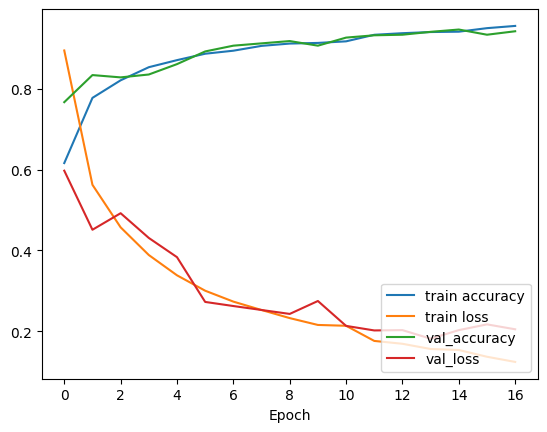

In [31]:
plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['loss'], label = 'train loss')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.plot(history.history['val_loss'], label = 'val_loss')

plt.xlabel('Epoch')
plt.legend(loc='lower right')


In [32]:
# evaluating on test
# test_loss, test_acc = model.evaluate(test_dataset, verbose=2)

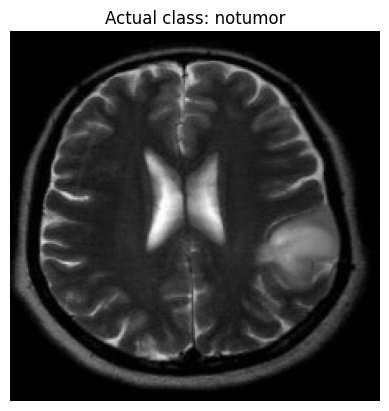

Actual class: notumor
Predicted class: notumor
Confidence: 99.98%


In [33]:
# prediction

# getting an image from test data

for images , labels in test_dataset.take(1):
    sample = images[0].numpy()
    true_label = label_encoder.classes_[tf.argmax(labels[0]).numpy()]


plt.imshow(sample)
plt.title(f"Actual class: {true_label}")
plt.axis("off")
plt.show()

#getting the best model from checkpoint

best_model = tf.keras.models.load_model(
    "/kaggle/working/checkpoints/best_model.keras"
)

#predicting
probas = best_model.predict( np.expand_dims(sample, axis=0), verbose=0 )[0]

predicted_index = np.argmax(probas)
predicted_class = label_encoder.classes_[predicted_index]
confidence = probas[predicted_index] * 100
print("Actual class:", true_label)
print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

In [38]:
!pip install  pydot
!apt-get -qq install graphviz

In [ ]:


plot_model(
    best_model,
    to_file="cnn_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    expand_nested=True,
    dpi=100
)

# display(Image(filename="cnn_architecture.png"))

You must install pydot (`pip install pydot`) for `plot_model` to work.


FileNotFoundError: [Errno 2] No such file or directory: 'cnn_architecture.png'

In [41]:
import shutil

shutil.copy2(
    "/kaggle/working/checkpoints/best_model.keras",
    "/kaggle/working/best_model.keras"
)

'/kaggle/working/best_model.keras'